# Network Analytics

---

In [1]:
import pickle
import numpy as np

with open('../../01-Dataset/graph_network.pkl', 'rb') as file:
    G = pickle.load(file)
    
node_labels = np.load('../../01-Dataset/node_labels.npy')

In [2]:
profiles = {
    0: 'Impulsive',
    1: 'Analytical',
    2: 'Gambler'
}

---

## Network Metrics:

In [13]:
import networkx as nx

degree_cen = nx.degree_centrality(G)
betweenness_cen = nx.betweenness_centrality(G)
clustering_coeff = nx.clustering(G)

In [14]:
metrics = []

for i, node in enumerate(G.nodes()):
    metrics.append({
        'Node_ID': node,
        'Profile': profiles[node_labels[i]],
        'Degree_Centrality': degree_cen[node],
        'Betweenness': betweenness_cen[node],
        'Clustering_Coeff': clustering_coeff[node]
    })

In [5]:
import pandas as pd

df_metrics = pd.DataFrame(metrics)
display(df_metrics)

,Node ID,Profile,Degree Centrality,Betweennesss,clustering_Coeff
0,0,Gambler,0.402685,0.402685,0.906780
1,1,Analytical,0.315436,0.315436,0.930620
2,2,Gambler,0.355705,0.355705,0.981132
3,3,Analytical,0.302013,0.302013,0.976768
4,4,Impulsive,0.449664,0.449664,0.823609
...,...,...,...,...,...
145,145,Gambler,0.684564,0.684564,0.614638
146,146,Analytical,0.302013,0.302013,0.976768
147,147,Analytical,0.308725,0.308725,0.971014
148,148,Gambler,0.536913,0.536913,0.712975


---

## Visualization:

ValueError: Could not interpret value `Degree_Centrality` for `y`. An entry with this name does not appear in `data`.

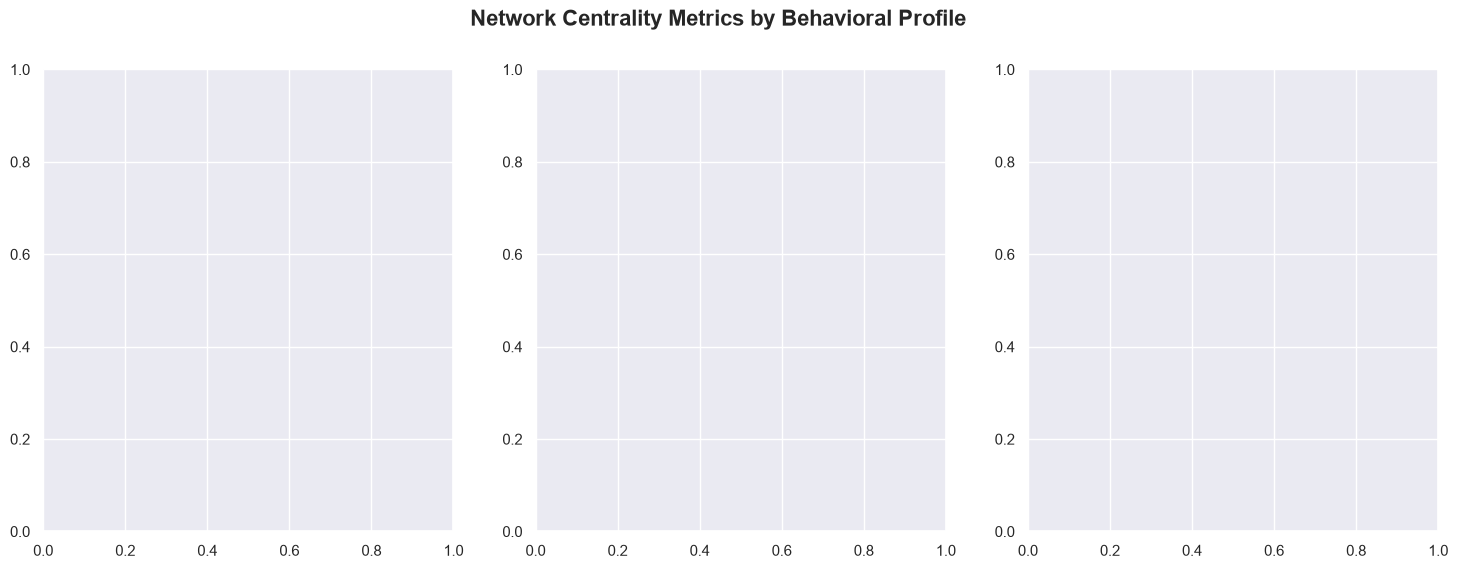

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Set the aesthetic style for a professional portfolio look
sns.set_theme(style="darkgrid")

# 2. Create a wide canvas with 3 side-by-side subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Network Centrality Metrics by Behavioral Profile', fontsize=16, weight='bold')

# 3. Plot Degree Centrality (The Influencer Metric)
sns.violinplot(ax=axes[0], data=df_metrics, x='Profile', y='Degree_Centrality', hue='Profile', palette='muted', legend=False)
axes[0].set_title('Degree Centrality (Connectivity)')
axes[0].set_ylabel('Score')

# 4. Plot Betweenness Centrality (The Bridge Metric)
sns.violinplot(ax=axes[1], data=df_metrics, x='Profile', y='Betweenness', hue='Profile', palette='muted', legend=False)
axes[1].set_title('Betweenness Centrality (Bridges)')
axes[1].set_ylabel('Score')

# 5. Plot Clustering Coefficient (The Echo Chamber Metric)
sns.violinplot(ax=axes[2], data=df_metrics, x='Profile', y='Clustering_Coeff', hue='Profile', palette='muted', legend=False)
axes[2].set_title('Clustering Coefficient (Echo Chamber)')
axes[2].set_ylabel('Score')

# Clean up layout and render
plt.tight_layout()
plt.show()